In [54]:
import pandas as pd

df = pd.read_csv("final_merge.csv")

# changing date_time to datetime type
df["date_time"] = pd.to_datetime(df["date_time"])


df.info()

<class 'pandas.DataFrame'>
RangeIndex: 317135 entries, 0 to 317134
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   client_id         317135 non-null  int64         
 1   visitor_id        317135 non-null  str           
 2   visit_id          317135 non-null  str           
 3   process_step      317135 non-null  str           
 4   date_time         317135 non-null  datetime64[us]
 5   variation         317135 non-null  str           
 6   clnt_tenure_yr    317135 non-null  int64         
 7   clnt_tenure_mnth  317135 non-null  int64         
 8   clnt_age          317135 non-null  float64       
 9   gendr             317135 non-null  str           
 10  num_accts         317135 non-null  int64         
 11  bal               317135 non-null  float64       
 12  calls_6_mnth      317135 non-null  int64         
 13  logons_6_mnth     317135 non-null  int64         
dtypes: datetime64[u

In [55]:
# Taking columns that will be used
df_demographic = ["client_id", "visit_id", "variation", "gendr", "clnt_age"]



In [56]:
# First "start" and last "confirm" of each visit
start_time = df[df["process_step"] == "start"].groupby(df_demographic)["date_time"].min()

confirm_time = df[df["process_step"] == "confirm"].groupby(df_demographic)["date_time"].max()

#putting them together
visits = pd.concat([start_time, confirm_time], axis=1, join="inner")
visits

,,,,,date_time,date_time
client_id,visit_id,variation,gendr,clnt_age,,
555,637149525_38041617439_716659,Test,U,29.5,2017-04-15 12:57:56,2017-04-15 13:00:34
647,40369564_40101682850_311847,Test,M,57.5,2017-04-12 15:41:28,2017-04-12 15:47:45
1195,393817425_39015278493_996341,Control,M,54.5,2017-04-05 20:15:26,2017-04-05 20:19:31
1197,71862471_21202285428_848395,Control,U,28.5,2017-04-01 17:16:24,2017-04-01 17:17:59
1336,583743392_96265099036_939815,Test,M,42.0,2017-05-08 06:05:12,2017-05-08 06:08:43
...,...,...,...,...,...,...
9998773,980310183_14300639078_417437,Test,U,28.5,2017-04-12 23:45:27,2017-04-12 23:50:22
9998851,310744937_17135608286_213964,Test,U,23.5,2017-04-05 12:05:58,2017-04-05 12:08:43
9999009,149965839_24823291142_245569,Test,M,68.5,2017-03-31 07:17:45,2017-03-31 07:20:36


In [57]:
#Changing the name of columns so they don't have the same
visits.columns = ["start_time", "confirm_time"]
visits = visits.reset_index()
visits

,client_id,visit_id,variation,gendr,clnt_age,start_time,confirm_time
0,555,637149525_38041617439_716659,Test,U,29.5,2017-04-15 12:57:56,2017-04-15 13:00:34
1,647,40369564_40101682850_311847,Test,M,57.5,2017-04-12 15:41:28,2017-04-12 15:47:45
2,1195,393817425_39015278493_996341,Control,M,54.5,2017-04-05 20:15:26,2017-04-05 20:19:31
3,1197,71862471_21202285428_848395,Control,U,28.5,2017-04-01 17:16:24,2017-04-01 17:17:59
4,1336,583743392_96265099036_939815,Test,M,42.0,2017-05-08 06:05:12,2017-05-08 06:08:43
...,...,...,...,...,...,...,...
32888,9998773,980310183_14300639078_417437,Test,U,28.5,2017-04-12 23:45:27,2017-04-12 23:50:22
32889,9998851,310744937_17135608286_213964,Test,U,23.5,2017-04-05 12:05:58,2017-04-05 12:08:43
32890,9999009,149965839_24823291142_245569,Test,M,68.5,2017-03-31 07:17:45,2017-03-31 07:20:36
32891,9999400,288904166_90826265353_276104,Test,U,28.5,2017-04-20 05:21:28,2017-04-20 05:23:27


In [58]:
# Total time in seconds
visits["total_seconds"] = (visits["confirm_time"] - visits["start_time"]).dt.total_seconds()
visits

,client_id,visit_id,variation,gendr,clnt_age,start_time,confirm_time,total_seconds
0,555,637149525_38041617439_716659,Test,U,29.5,2017-04-15 12:57:56,2017-04-15 13:00:34,158.0
1,647,40369564_40101682850_311847,Test,M,57.5,2017-04-12 15:41:28,2017-04-12 15:47:45,377.0
2,1195,393817425_39015278493_996341,Control,M,54.5,2017-04-05 20:15:26,2017-04-05 20:19:31,245.0
3,1197,71862471_21202285428_848395,Control,U,28.5,2017-04-01 17:16:24,2017-04-01 17:17:59,95.0
4,1336,583743392_96265099036_939815,Test,M,42.0,2017-05-08 06:05:12,2017-05-08 06:08:43,211.0
...,...,...,...,...,...,...,...,...
32888,9998773,980310183_14300639078_417437,Test,U,28.5,2017-04-12 23:45:27,2017-04-12 23:50:22,295.0
32889,9998851,310744937_17135608286_213964,Test,U,23.5,2017-04-05 12:05:58,2017-04-05 12:08:43,165.0
32890,9999009,149965839_24823291142_245569,Test,M,68.5,2017-03-31 07:17:45,2017-03-31 07:20:36,171.0
32891,9999400,288904166_90826265353_276104,Test,U,28.5,2017-04-20 05:21:28,2017-04-20 05:23:27,119.0


In [59]:
visits.count()

client_id        32893
visit_id         32893
variation        32893
gendr            32893
clnt_age         32893
start_time       32893
confirm_time     32893
total_seconds    32893
dtype: int64

In [60]:
# Removing negative seconds
visits = visits[visits["total_seconds"] > 0]


In [61]:
visits.groupby("gendr")["total_seconds"].describe([0.5, 0.75, 0.85])

,count,mean,std,min,50%,75%,85%,max
gendr,,,,,,,,
F,10168.0,422.283340,588.891880,32.0,266.0,471.25,673.95,18015.0
M,11219.0,414.490596,478.687061,38.0,271.0,468.00,655.00,7947.0
U,11469.0,388.990409,494.252495,33.0,249.0,436.00,608.00,9994.0


In [62]:
#Using iqr rule for the outliers
q1 = visits["total_seconds"].quantile(0.25)
q3 = visits["total_seconds"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

visits = visits[visits["total_seconds"] <= upper_limit]

display(upper_limit)
display(visits)

np.float64(895.5)

,client_id,visit_id,variation,gendr,clnt_age,start_time,confirm_time,total_seconds
0,555,637149525_38041617439_716659,Test,U,29.5,2017-04-15 12:57:56,2017-04-15 13:00:34,158.0
1,647,40369564_40101682850_311847,Test,M,57.5,2017-04-12 15:41:28,2017-04-12 15:47:45,377.0
2,1195,393817425_39015278493_996341,Control,M,54.5,2017-04-05 20:15:26,2017-04-05 20:19:31,245.0
3,1197,71862471_21202285428_848395,Control,U,28.5,2017-04-01 17:16:24,2017-04-01 17:17:59,95.0
4,1336,583743392_96265099036_939815,Test,M,42.0,2017-05-08 06:05:12,2017-05-08 06:08:43,211.0
...,...,...,...,...,...,...,...,...
32888,9998773,980310183_14300639078_417437,Test,U,28.5,2017-04-12 23:45:27,2017-04-12 23:50:22,295.0
32889,9998851,310744937_17135608286_213964,Test,U,23.5,2017-04-05 12:05:58,2017-04-05 12:08:43,165.0
32890,9999009,149965839_24823291142_245569,Test,M,68.5,2017-03-31 07:17:45,2017-03-31 07:20:36,171.0
32891,9999400,288904166_90826265353_276104,Test,U,28.5,2017-04-20 05:21:28,2017-04-20 05:23:27,119.0


In [63]:
# upper_limit in minutes
upper_limit / 60

np.float64(14.925)

In [64]:
# Checking the total of each group
visits["gendr"].value_counts()

gendr
U    10594
M    10245
F     9219
Name: count, dtype: int64

In [65]:
# Keeping only F and M since U (unknown) won't tell anything
visits_gender = visits[(visits["gendr"] == "F") | (visits["gendr"] == "M")]
visits_gender

,client_id,visit_id,variation,gendr,clnt_age,start_time,confirm_time,total_seconds
1,647,40369564_40101682850_311847,Test,M,57.5,2017-04-12 15:41:28,2017-04-12 15:47:45,377.0
2,1195,393817425_39015278493_996341,Control,M,54.5,2017-04-05 20:15:26,2017-04-05 20:19:31,245.0
4,1336,583743392_96265099036_939815,Test,M,42.0,2017-05-08 06:05:12,2017-05-08 06:08:43,211.0
6,1643,753205700_16851596206_134483,Test,M,55.0,2017-06-10 07:49:27,2017-06-10 08:00:55,688.0
7,1755,420603142_53705621002_674558,Test,M,46.5,2017-04-02 11:50:21,2017-04-02 11:54:04,223.0
...,...,...,...,...,...,...,...,...
32881,9996711,200256953_19881035574_656660,Control,M,42.5,2017-04-21 19:09:21,2017-04-21 19:20:47,686.0
32883,9997114,19940015_3197786491_51650,Control,M,44.5,2017-04-14 20:16:33,2017-04-14 20:21:31,298.0
32887,9998346,189177304_69869411700_783154,Control,F,61.5,2017-03-29 15:25:00,2017-03-29 15:37:28,748.0
32890,9999009,149965839_24823291142_245569,Test,M,68.5,2017-03-31 07:17:45,2017-03-31 07:20:36,171.0


In [66]:
#cheking the oldest client
visits['clnt_age'].max()

np.float64(95.5)

In [67]:
age_bins = [0, 30, 45, 60, 100]
age_labels = ["≤ 30", "31–45", "46–60", "61+"]
#creating the column age_group to classify clients 
visits["age_group"] = pd.cut(visits["clnt_age"], bins=age_bins, labels=age_labels)
# making visits_gender again to add the new column (age_group)
visits_gender = visits[(visits["gendr"] == "F") | (visits["gendr"] == "M")]
visits[["clnt_age", "age_group"]]

,clnt_age,age_group
0,29.5,≤ 30
1,57.5,46–60
2,54.5,46–60
3,28.5,≤ 30
4,42.0,31–45
...,...,...
32888,28.5,≤ 30
32889,23.5,≤ 30
32890,68.5,61+
32891,28.5,≤ 30


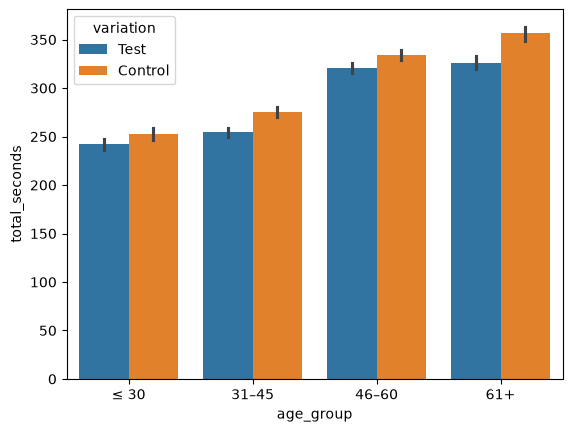

In [68]:
ax = sns.barplot(data=visits, x="age_group", y="total_seconds", hue="variation")


In [69]:
# getting the mean of each group of age per variation

younger_control = visits[(visits["age_group"] == "≤ 30") & (visits["variation"] == "Control")]["total_seconds"].mean()
younger_test = visits[(visits["age_group"] == "≤ 30") & (visits["variation"] == "Test")]["total_seconds"].mean()

age31_45_control = visits[(visits["age_group"] == "31–45") & (visits["variation"] == "Control")]["total_seconds"].mean()
age31_45_test = visits[(visits["age_group"] == "31–45") & (visits["variation"] == "Test")]["total_seconds"].mean()

age46_60_control = visits[(visits["age_group"] == "46–60") & (visits["variation"] == "Control")]["total_seconds"].mean()
age46_60_test = visits[(visits["age_group"] == "46–60") & (visits["variation"] == "Test")]["total_seconds"].mean()

older_control = visits[(visits["age_group"] == "61+") & (visits["variation"] == "Control")]["total_seconds"].mean()
older_test = visits[(visits["age_group"] == "61+") & (visits["variation"] == "Test")]["total_seconds"].mean()

In [70]:
#getting the difference between control and test per age groups
younger_difference = younger_test - younger_control
age31_45_difference = age31_45_test - age31_45_control
age46_60_difference = age46_60_test - age46_60_control
older_difference = older_test - older_control

In [71]:
#getting the relative difference (%)
younger_difference_pct = younger_difference / younger_control * 100
age31_45_difference_pct = age31_45_difference / age31_45_control * 100
age46_60_difference_pct = age46_60_difference / age46_60_control * 100
older_difference_pct = older_difference / older_control * 100

In [72]:
# creating the table
age_means = pd.DataFrame({
    "age_group": ["≤ 30", "31–45", "46–60", "61+"],
    "Control": [younger_control, age31_45_control, age46_60_control, older_control],
    "Test": [younger_test, age31_45_test, age46_60_test, older_test],
    "difference_s (Test-Control)": [younger_difference, age31_45_difference, age46_60_difference, older_difference],
    "difference_%": [younger_difference_pct, age31_45_difference_pct, age46_60_difference_pct, older_difference_pct],
})

age_means.round(1)

,age_group,Control,Test,difference_s (Test-Control),difference_%
0,≤ 30,252.9,242.1,-10.8,-4.3
1,31–45,275.3,254.4,-20.9,-7.6
2,46–60,334.3,320.3,-14.0,-4.2
3,61+,356.3,325.9,-30.4,-8.5


In [73]:
#getting the total seconds of each for the welch's t-test
younger_test_times = visits[(visits["age_group"] == "≤ 30") & (visits["variation"] == "Test")]["total_seconds"]
younger_control_times = visits[(visits["age_group"] == "≤ 30") & (visits["variation"] == "Control")]["total_seconds"]

age31_45_test_times = visits[(visits["age_group"] == "31–45") & (visits["variation"] == "Test")]["total_seconds"]
age31_45_control_times = visits[(visits["age_group"] == "31–45") & (visits["variation"] == "Control")]["total_seconds"]

age46_60_test_times = visits[(visits["age_group"] == "46–60") & (visits["variation"] == "Test")]["total_seconds"]
age46_60_control_times = visits[(visits["age_group"] == "46–60") & (visits["variation"] == "Control")]["total_seconds"]

older_test_times = visits[(visits["age_group"] == "61+") & (visits["variation"] == "Test")]["total_seconds"]
older_control_times = visits[(visits["age_group"] == "61+") & (visits["variation"] == "Control")]["total_seconds"]

In [74]:
# Welch's t-test for each age group

younger_statistic, younger_p_value = st.ttest_ind(younger_test_times, younger_control_times, equal_var=False, alternative="two-sided")
age31_45_statistic, age31_45_p_value = st.ttest_ind(age31_45_test_times, age31_45_control_times, equal_var=False, alternative="two-sided")
age46_60_statistic, age46_60_p_value = st.ttest_ind(age46_60_test_times, age46_60_control_times, equal_var=False, alternative="two-sided")
older_statistic, older_p_value = st.ttest_ind(older_test_times, older_control_times, equal_var=False, alternative="two-sided")
younger_p_value, age31_45_p_value, age46_60_p_value, older_p_value

(np.float64(0.013786049062357785),
 np.float64(1.4182008859863735e-08),
 np.float64(0.00037704433256605807),
 np.float64(9.023783474197408e-10))

Conclusion
1. Older clients take longer to complete the process, in both designs.
2. The new design is faster in every age group.
3. The differences are not because of chance. (proven with p values being lower than 0.05)

In [75]:
# getting the average time of each gender in each variation
women_control = visits_gender[(visits_gender["gendr"] == "F") & (visits_gender["variation"] == "Control")]["total_seconds"].mean()
women_test = visits_gender[(visits_gender["gendr"] == "F") & (visits_gender["variation"] == "Test")]["total_seconds"].mean()
men_control = visits_gender[(visits_gender["gendr"] == "M") & (visits_gender["variation"] == "Control")]["total_seconds"].mean()
men_test = visits_gender[(visits_gender["gendr"] == "M") & (visits_gender["variation"] == "Test")]["total_seconds"].mean()


In [76]:
# getting the difference for each gender so we know if control is faster or not
women_difference = women_test - women_control
men_difference = men_test - men_control
men_difference, women_difference

(np.float64(-21.688096594997546), np.float64(-20.77293061907318))

In [77]:
# getting the relative difference
women_difference_pct = women_difference / women_control * 100
men_difference_pct = men_difference / men_control * 100
women_difference_pct, men_difference_pct

(np.float64(-6.717419422714806), np.float64(-6.87594628613444))

In [78]:
#creating the dataframe to display the results
gender_means = pd.DataFrame({
    "gender": ["F", "M"],
    "Control": [women_control, men_control],
    "Test": [women_test, men_test],
    "difference_s (Test-Control)": [women_difference, men_difference],
    "difference_%": [women_difference_pct, men_difference_pct],
}).set_index("gender")
gender_means

,Control,Test,difference_s (Test-Control),difference_%
gender,,,,
F,309.239744,288.466813,-20.772931,-6.717419
M,315.419808,293.731712,-21.688097,-6.875946


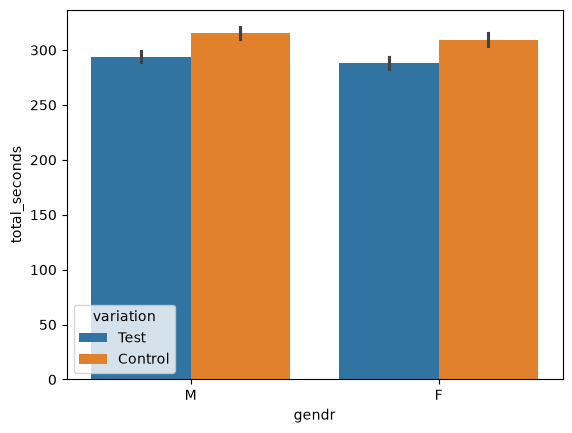

In [79]:
import seaborn as sns

ax = sns.barplot(data=visits_gender, x="gendr", y="total_seconds", hue="variation")

Welch's t-test for gender
H0: mu Test = mu Control, the new design doesn't change the average time for this gender
H1: mu Test ≠ mu Control,  the average time is different


In [80]:
alpha = 0.05
# getting the total seconds for each gender
women_test_times = visits_gender[(visits_gender["gendr"] == "F") & (visits_gender["variation"] == "Test")]["total_seconds"]
women_control_times = visits_gender[(visits_gender["gendr"] == "F") & (visits_gender["variation"] == "Control")]["total_seconds"]
men_test_times = visits_gender[(visits_gender["gendr"] == "M") & (visits_gender["variation"] == "Test")]["total_seconds"]
men_control_times = visits_gender[(visits_gender["gendr"] == "M") & (visits_gender["variation"] == "Control")]["total_seconds"]


In [81]:
import scipy.stats as st
women_statistic, women_p_value = st.ttest_ind(women_test_times, women_control_times, equal_var=False, alternative="two-sided")
women_p_value

np.float64(1.0771626133749074e-07)

In [82]:
men_statistic, men_p_value = st.ttest_ind(men_test_times, men_control_times, equal_var=False, alternative="two-sided")
men_p_value

np.float64(3.7691658108369e-09)

both reject h0: test is faster in both genders

In [ ]:
Conclusion
1. Genders behave almost exactly the same 